Find Source and Sink nodes.
Find tranistion nodes where there is only 1 possiblity
See what happens when I restirct to only pia icaos and real icaos that are known to use pia.

In [98]:
from pia.resolver import build_candidates
from datetime import date
from data_engineering.flights.flight_type import FlightIndex, flights_df_to_flights, get_flights, pia_or_american_ladd_icao_filter
import polars as pl
import networkx as nx

from pia.solver import resolve_links_with_margin
start_dt = date(2026, 1, 1)
end_dt = date(2026, 7, 1)
df_flights = get_flights(start_dt, end_dt)
df_flights = df_flights.filter(pia_or_american_ladd_icao_filter())
flights = flights_df_to_flights(df_flights)
flight_index = FlightIndex(flights, None)
candidates = build_candidates(flight_index)
selected_candidates, mapping, df_margins = resolve_links_with_margin(
    flight_index,
    candidates,
)

Found 2230681 overlapping ICAO pairs.
Total number of componenets: 6264
Number of selected candidates: 932473
Number of connected components: 14086
Number of connected components: 14086


# Investigating selected_candidates

In [103]:
df_mapping = pl.read_parquet('/Volumes/T2-SSD/planequery/data/tests/test_pia/test_real_flights_4/test_pia_test_real_flights_4_20260818_163723/pia_mapping_audit.parquet', glob=False)
correct_by_pia_icao = (
    df_mapping
    .unique("observed_icao")
    .select("observed_icao", "correct")
    .to_dict(as_series=False)
)
correct_by_pia_icao = dict(
    zip(
        correct_by_pia_icao["observed_icao"],
        correct_by_pia_icao["correct"],
    )
)

In [115]:
from pia.graph import create_graph_from_selected_candidates


def create_mapping_stats(graph: nx.DiGraph, flight_index: FlightIndex, mapping: dict):
    pia_icao_mapping_stats = dict()
    for nodes in nx.weakly_connected_components(graph):
        component = graph.subgraph(nodes)
        longest_path = nx.dag_longest_path(component)
        path_edges = [
        (u, v, component.edges[u, v])
        for u, v in nx.utils.pairwise(longest_path)
        ]
        score = 0
        for u, v, edge_data in path_edges:
            score += edge_data["score"]
        number_of_flights = len(longest_path)
        # calculate score on this.
        pia_icaos = set()
        for node in longest_path:
            flight = flight_index.get_flight_by_id(node)
            if flight.icao in mapping:
                pia_icaos.add(flight.icao)
        for pia_icao in pia_icaos:
            if pia_icao in correct_by_pia_icao:
                correct = correct_by_pia_icao[pia_icao]
            else:
                correct = None
            pia_icao_mapping_stats[pia_icao] = {
                "score": score,
                "number_of_flights": number_of_flights,
                "correct": correct,
            }
    return pia_icao_mapping_stats
from pia.solver import pia_icao_mapping_from_selected_candidates

pia_icao_mapping = pia_icao_mapping_from_selected_candidates(
    selected_candidates,
    flight_index,
)

graph = create_graph_from_selected_candidates(selected_candidates, flight_index)
pia_icao_mapping_stats = create_mapping_stats(
    graph,
    flight_index,
    pia_icao_mapping,
)

Number of connected components: 14086
Number of connected components: 14086


In [117]:
pia_icao_mapping_stats_new = {
    pia_icao: stats
    for pia_icao, stats in pia_icao_mapping_stats.items()
    if stats["correct"] is not None
}
pia_icao_mapping_stats_new

{'a03d71': {'score': 173500, 'number_of_flights': 56, 'correct': True},
 'a0ff21': {'score': 167250, 'number_of_flights': 52, 'correct': False},
 'a03f2c': {'score': 197750, 'number_of_flights': 58, 'correct': True},
 'a038e5': {'score': 284500, 'number_of_flights': 81, 'correct': False},
 'a091e6': {'score': 203000, 'number_of_flights': 56, 'correct': True},
 'a03bc7': {'score': 243750, 'number_of_flights': 73, 'correct': True},
 'a03c06': {'score': 80250, 'number_of_flights': 25, 'correct': False},
 'a0fef7': {'score': 17250, 'number_of_flights': 7, 'correct': True},
 'a0fefb': {'score': 100500, 'number_of_flights': 30, 'correct': False},
 'a0ff09': {'score': 159750, 'number_of_flights': 47, 'correct': True},
 'a0feaf': {'score': 107000, 'number_of_flights': 33, 'correct': False},
 'a0c436': {'score': 9000, 'number_of_flights': 4, 'correct': False},
 'a09201': {'score': 89750, 'number_of_flights': 28, 'correct': False},
 'a0fe45': {'score': 3750, 'number_of_flights': 3, 'correct': Fa

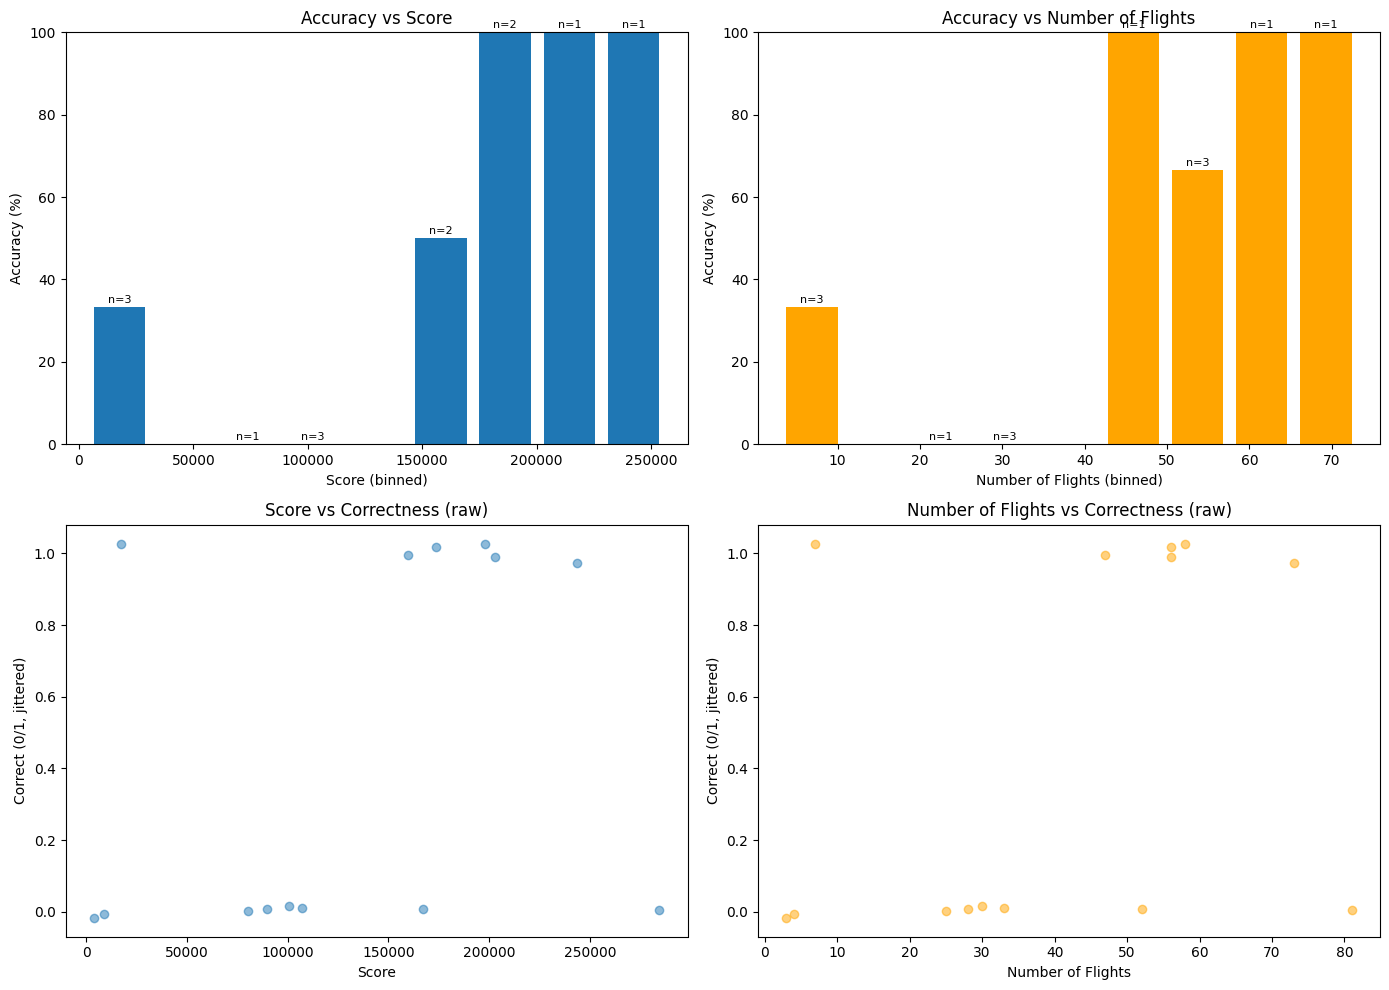

In [ ]:
import numpy as np

import matplotlib.pyplot as plt

# Filter to only entries with known correctness
known_stats = [
    stats for stats in pia_icao_mapping_stats.values()
    if stats["correct"] is not None
]

scores = np.array([s["score"] for s in known_stats])
num_flights = np.array([s["number_of_flights"] for s in known_stats])
correct = np.array([s["correct"] for s in known_stats], dtype=float)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Score vs Accuracy (binned) ---
score_bins = np.linspace(scores.min(), scores.max(), 11)
score_bin_idx = np.digitize(scores, score_bins) - 1
score_bin_centers = (score_bins[:-1] + score_bins[1:]) / 2
score_accuracy = [
    correct[score_bin_idx == i].mean() * 100 if np.any(score_bin_idx == i) else np.nan
    for i in range(len(score_bins) - 1)
]
score_counts = [np.sum(score_bin_idx == i) for i in range(len(score_bins) - 1)]

axes[0, 0].bar(score_bin_centers, score_accuracy, width=(score_bins[1]-score_bins[0])*0.8)
axes[0, 0].set_xlabel("Score (binned)")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].set_title("Accuracy vs Score")
axes[0, 0].set_ylim(0, 100)

# annotate counts
for x, y, c in zip(score_bin_centers, score_accuracy, score_counts):
    if not np.isnan(y):
        axes[0, 0].text(x, y + 1, f"n={c}", ha="center", fontsize=8)

# --- Number of flights vs Accuracy (binned) ---
nf_bins = np.linspace(num_flights.min(), num_flights.max(), 11)
nf_bin_idx = np.digitize(num_flights, nf_bins) - 1
nf_bin_centers = (nf_bins[:-1] + nf_bins[1:]) / 2
nf_accuracy = [
    correct[nf_bin_idx == i].mean() * 100 if np.any(nf_bin_idx == i) else np.nan
    for i in range(len(nf_bins) - 1)
]
nf_counts = [np.sum(nf_bin_idx == i) for i in range(len(nf_bins) - 1)]

axes[0, 1].bar(nf_bin_centers, nf_accuracy, width=(nf_bins[1]-nf_bins[0])*0.8, color="orange")
axes[0, 1].set_xlabel("Number of Flights (binned)")
axes[0, 1].set_ylabel("Accuracy (%)")
axes[0, 1].set_title("Accuracy vs Number of Flights")
axes[0, 1].set_ylim(0, 100)

for x, y, c in zip(nf_bin_centers, nf_accuracy, nf_counts):
    if not np.isnan(y):
        axes[0, 1].text(x, y + 1, f"n={c}", ha="center", fontsize=8)

# --- Scatter: Score vs Correct (jittered) ---
jitter = np.random.uniform(-0.03, 0.03, size=len(correct))
axes[1, 0].scatter(scores, correct + jitter, alpha=0.5)
axes[1, 0].set_xlabel("Score")
axes[1, 0].set_ylabel("Correct (0/1, jittered)")
axes[1, 0].set_title("Score vs Correctness (raw)")

# --- Scatter: Number of Flights vs Correct (jittered) ---
axes[1, 1].scatter(num_flights, correct + jitter, alpha=0.5, color="orange")
axes[1, 1].set_xlabel("Number of Flights")
axes[1, 1].set_ylabel("Correct (0/1, jittered)")
axes[1, 1].set_title("Number of Flights vs Correctness (raw)")

plt.tight_layout()
plt.show()

In [65]:
len(mapping)

95

In [67]:
len(pia_icao_mapping_stats)

95